<a href="https://colab.research.google.com/github/KushagraPan/machine-learning-zoomcamp/blob/main/Classification_HW3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning Zoomcamp 2026 — Classification Homework 3

### Homework workflow

1. Load and inspect the 2026 lead-scoring data
2. Handle missing values
3. Q1 — find the most frequent `industry`
4. Q2/Q3 — analyze correlations / mutual information
5. Split into train, validation, and test sets
6. Q4 — train logistic regression with all 8 predictor features
7. Q5 — eliminate one feature at a time
8. Q6 — compare different regularization strengths (`C`)

In [ ]:
!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv


--2026-10-15 20:46:16--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv.5’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.02s   

2026-10-15 20:46:16 (13.6 MB/s) - ‘course_lead_scoring_2026.csv.5’ saved [278746/278746]



## 1. Load the dataset

We use the **2026 course lead scoring dataset** supplied for this cohort.

`converted` is the target variable:
- `1` = lead converted
- `0` = lead did not convert

The predictors are the other columns.


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


df = pd.read_csv('course_lead_scoring_2026.csv')
df.head(20)
df.converted.value_counts()

,count
converted,
1,2883
0,2117


## 2. Check missing values

Before modelling, we need to know which columns contain missing values.

`df.isnull().sum()` counts the missing (`NaN`) values in every column.


In [ ]:
# Check for missing values in the DataFrame
missing_values = df.isnull().sum()
display(missing_values)

,0
lead_source,148
industry,240
employment_status,194
location,208
annual_income,369
number_of_courses_viewed,0
interaction_count,0
lead_score,35
converted,0


## 3. Handle missing values

The homework requires:
- categorical missing values → `'NA'`
- numerical missing values → `0.0`



In [ ]:
# Fill missing values
categorical_cols = ['lead_source', 'industry', 'employment_status', 'location']
numerical_cols = ['annual_income', 'lead_score']

for col in categorical_cols:
    df[col] = df[col].fillna('NA')

for col in numerical_cols:
    df[col] = df[col].fillna(0.0)

# Verify that no missing values remain
print("Missing values after imputation:")
print(df.isnull().sum())

# Display the first few rows to confirm
display(df.head())

Missing values after imputation:
lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Q1 — Most frequent `industry`


In [ ]:
#Most frequent observation (mode) for the column industry
industry_mode = df['industry'].mode()[0]
print(f"The most frequent observation (mode) for the column 'industry' is: {industry_mode}")

The most frequent observation (mode) for the column 'industry' is: technology


## Q2/Q3 — Correlation analysis

`.corr()` calculates Pearson correlation coefficients between the selected numerical variables.

By selecting:

```python
correlation_matrix['converted']
```

we are asking:

> How strongly is each numerical feature linearly associated with the target `converted`?

A value closer to `+1` means a stronger positive linear relationship; a value near `0` means a weaker linear relationship.


In [ ]:
#Create the correlation matrix for the numerical features of your dataset. In a correlation matrix, you compute the correlation coefficient between every pair of features.
numerical_cols = ['annual_income', 'lead_score','number_of_courses_viewed','interaction_count','converted']
correlation_matrix = df[numerical_cols].corr()

print(correlation_matrix['converted'].sort_values(ascending=False))

converted                   1.000000
lead_score                  0.483246
interaction_count           0.448624
number_of_courses_viewed    0.395038
annual_income               0.189652
Name: converted, dtype: float64


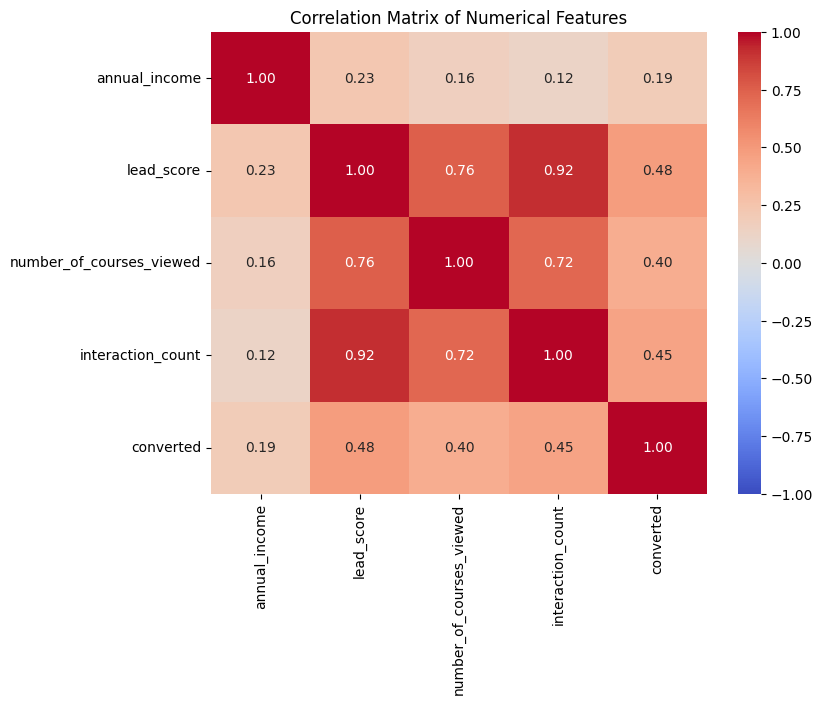

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

## 4. Train / validation / test split

We first create:

- 80% `df_full_train`
- 20% `df_test`

Then split the 80% training portion into:

- 75% `df_train`
- 25% `df_val`

So the final proportions are:

```text
60% train = 3000 rows
20% validation = 1000 rows
20% test = 1000 rows
```

`random_state=42` makes the split reproducible.


In [ ]:
from sklearn.model_selection import train_test_split

# Split the data into training, validation, and test sets

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)
# Reset indexes
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Save targets
y_train = df_train.converted
y_val = df_val.converted
y_test = df_test.converted

del df_test['converted']
del df_val['converted']
del df_train['converted']


## Q3 — Mutual Information for categorical features

Mutual Information (MI) measures how much information a categorical feature provides about the target.

Here we calculate MI for the four categorical features:

- `lead_source`
- `industry`
- `employment_status`
- `location`

Higher MI means a stronger statistical dependency with `converted`.

In [ ]:
#mutual information
from sklearn.metrics import mutual_info_score
def calculate_mi(series):
    return mutual_info_score(series, df_full_train.converted)

df_mi = df_full_train[categorical_cols].apply(calculate_mi)
df_mi = df_mi.sort_values(ascending=False).to_frame(name='MI')

display(df_mi.head())


,MI
lead_source,0.034761
employment_status,0.020313
industry,0.002898
location,0.001050


## Q4 — Prepare the full feature set

This is the important Q4 baseline.

We use **all 8 predictor features**:

### Categorical
- `lead_source`
- `industry`
- `employment_status`
- `location`

### Numerical
- `annual_income`
- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`

`converted` is the target, so it must NOT be included in `X`.

`DictVectorizer` performs one-hot encoding for the categorical variables and converts the records into a numerical matrix.


In [ ]:
#let's train a logistic regression.First one hot encoding of categorical variables
from sklearn.feature_extraction import DictVectorizer
dv = DictVectorizer(sparse=False)
#Remove Converted from numerical columns for training
numerical_cols.pop()

train_dict = df_train[categorical_cols + numerical_cols].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)
val_dict = df_val[categorical_cols + numerical_cols].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [ ]:
print(X_train.shape)
print(X_val.shape)

(3000, 28)
(1000, 28)


## Q4 — Train logistic regression

The homework specifies these parameters:

```python
solver='liblinear'
C=1.0
max_iter=1000
random_state=42
```

We fit the model on the **training set only**.

The validation set is kept aside to evaluate the model after training.


In [ ]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)


LogisticRegression(max_iter=1000, random_state=42, solver='liblinear')

In [ ]:
model.intercept_[0]

np.float64(-0.010838978497809288)

In [ ]:
model.coef_[0].round(3)

array([-0.   , -0.001,  0.007, -0.003, -0.008, -0.006, -0.   , -0.003,
       -0.001, -0.002, -0.002, -0.002, -0.001,  0.137,  0.011,  0.   ,
       -0.009,  0.007, -0.014,  0.009, -0.004,  0.   , -0.002, -0.002,
       -0.001, -0.003, -0.004,  0.054])

## Q4 — Predict conversion probabilities

`predict_proba(X_val)` returns two probabilities for every validation row:

```text
probability of class 0
probability of class 1
```

`[:, 1]` selects the probability of class `1`, i.e. the probability that the lead converts.


In [ ]:
y_pred = model.predict_proba(X_val)[:,1]


## Q4 — Convert probabilities into predictions

We use the standard 0.5 threshold:

```text
probability >= 0.5 → predict 1 / converted
probability < 0.5  → predict 0 / not converted
```

The result is a Boolean array (`True`/`False`).


In [ ]:
is_converted = (y_pred >= 0.5)

trues = is_converted.sum()
falses = len(is_converted) - trues

print(f"Trues: {trues}, Falses: {falses}")


Trues: 874, Falses: 126


## Q4 — Calculate validation accuracy

```python
is_converted == y_val
```

compares every prediction with the true validation label.

It produces `True` for a correct prediction and `False` for an incorrect one.

`.mean()` converts that into the fraction of correct predictions.




In [ ]:
accuracy = (is_converted == y_val).mean().round(2)
accuracy

np.float64(0.64)

## Q5 — Feature elimination

Q5 starts from the **same full 8-feature set used in Q4**.

We remove one candidate feature at a time:

1. `lead_source`
2. `number_of_courses_viewed`
3. `interaction_count`

For each experiment:

```text
remove one feature
      ↓
rebuild the one-hot encoded matrix
      ↓
train the same logistic regression
      ↓
calculate validation accuracy
      ↓
compare with the Q4 baseline (0.645)
```




In [ ]:
features = [
    'lead_source',
    'industry',
    'employment_status',
    'location',
    'annual_income',
    'lead_score',
    'number_of_courses_viewed',
    'interaction_count'
]

features_to_remove = [
    'lead_source',
    'number_of_courses_viewed',
    'interaction_count'
]

for feature in features_to_remove:

    current_features = [
        f for f in features
        if f != feature
    ]

    train_dict_q5 = df_train[current_features].to_dict(orient='records')
    val_dict_q5 = df_val[current_features].to_dict(orient='records')

    dv_q5 = DictVectorizer(sparse=False)

    X_train_q5 = dv_q5.fit_transform(train_dict_q5)
    X_val_q5 = dv_q5.transform(val_dict_q5)

    model_q5 = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000,
        random_state=42
    )

    model_q5.fit(X_train_q5, y_train)

    y_pred_q5 = model_q5.predict_proba(X_val_q5)[:, 1]

    is_converted_q5 = y_pred_q5 >= 0.5

    accuracy_q5 = (is_converted_q5 == y_val).mean()

    print(
        feature,
        "accuracy =", accuracy_q5,
        "difference =", 0.645 - accuracy_q5
    )

lead_source accuracy = 0.642 difference = 0.0030000000000000027
number_of_courses_viewed accuracy = 0.643 difference = 0.0020000000000000018
interaction_count accuracy = 0.601 difference = 0.04400000000000004


## Q6 — Tune the regularization parameter `C`

Q6 goes back to the **full 8-feature Q4 matrices**.

Only `C` changes.

We test:

```python
[0.000001, 0.00001, 0.0001, 0.001]
```

Smaller `C` means stronger regularization.

For each value, we:
1. create a new logistic regression model,
2. train it on the same `X_train`,
3. evaluate it on the same `X_val`,
4. compare validation accuracy.
results:



In [ ]:
C_values = [0.000001, 0.00001, 0.0001, 0.001]

for C in C_values:

    model_q6 = LogisticRegression(
        solver='liblinear',
        C=C,
        max_iter=1000,
        random_state=42
    )

    model_q6.fit(X_train, y_train)

    y_pred_q6 = model_q6.predict_proba(X_val)[:, 1]

    is_converted_q6 = y_pred_q6 >= 0.5

    accuracy_q6 = (is_converted_q6 == y_val).mean()

    print(C, round(accuracy_q6, 3))

1e-06 0.598
1e-05 0.598
0.0001 0.613
0.001 0.645
